# Facial Emotion Recognition — Model Training

This notebook trains and evaluates a **facial-expression image** classifier from the local FER-style `train/` and `test/` folders. It extracts HOG (Histogram of Oriented Gradients) descriptors, compares a majority-class baseline, logistic regression, and a linear SVM on a stratified validation split, then evaluates the selected model once on the held-out test set.

It writes a separate facial-emotion model and infographic-quality charts under `ml/face_emotion/outputs/` and `ml/face_emotion/model/`. It does **not** replace the audio model in `ml/voice_emotion/`; the two tasks use different input modalities.

In [1]:
from pathlib import Path
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from skimage.feature import hog

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
IMAGE_SIZE = (48, 48)
CLASS_NAMES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "ml").is_dir() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project root containing both 'ml/' and 'src/'.")

PROJECT_ROOT = find_project_root(Path.cwd())
DATA_ROOT = PROJECT_ROOT.parent
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"
OUTPUT_DIR = PROJECT_ROOT / "ml" / "face_emotion" / "outputs"
MODEL_DIR = PROJECT_ROOT / "ml" / "face_emotion" / "model"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for split_dir in (TRAIN_DIR, TEST_DIR):
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Expected labeled image folders at {split_dir}")
    found_classes = {p.name for p in split_dir.iterdir() if p.is_dir()}
    if found_classes != set(CLASS_NAMES):
        raise ValueError(f"Unexpected classes in {split_dir}: {sorted(found_classes)}")

print(f"Project: {PROJECT_ROOT}")
print(f"Dataset: {DATA_ROOT}")
print(f"Training images: {TRAIN_DIR}")
print(f"Test images: {TEST_DIR}")

Project: C:\Users\POOJASRI M\Documents\suganth\cog-nito-care
Dataset: C:\Users\POOJASRI M\Documents\suganth
Training images: C:\Users\POOJASRI M\Documents\suganth\train
Test images: C:\Users\POOJASRI M\Documents\suganth\test


## Dataset overview

The source already provides a labeled train/test split. The training split is further divided for model selection; the provided test split remains untouched until final evaluation.

,Training images,Test images
angry,3995,958
disgust,436,111
fear,4097,1024
happy,7215,1774
neutral,4965,1233
sad,4830,1247
surprise,3171,831


Total: 28,709 train + 7,178 test images


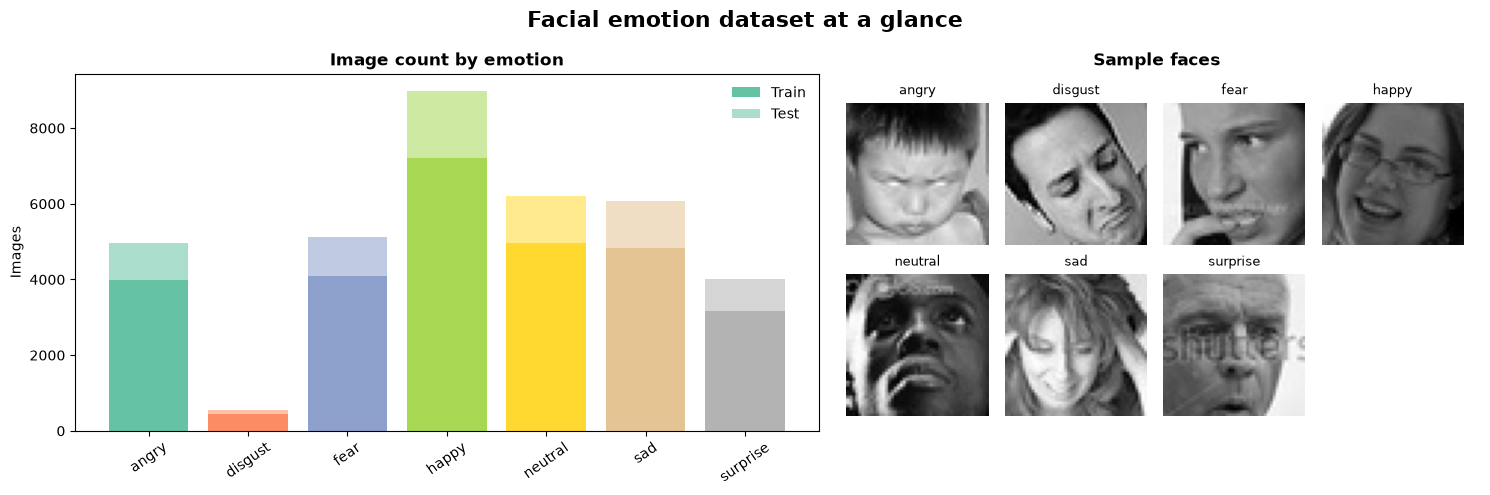

In [2]:
def image_paths_by_class(split_dir: Path) -> dict[str, list[Path]]:
    extensions = {".jpg", ".jpeg", ".png"}
    return {
        class_name: sorted(
            p for p in (split_dir / class_name).rglob("*")
            if p.is_file() and p.suffix.lower() in extensions
        )
        for class_name in CLASS_NAMES
    }

train_paths = image_paths_by_class(TRAIN_DIR)
test_paths = image_paths_by_class(TEST_DIR)
train_counts = pd.Series({name: len(train_paths[name]) for name in CLASS_NAMES}, name="Training images")
test_counts = pd.Series({name: len(test_paths[name]) for name in CLASS_NAMES}, name="Test images")
dataset_summary = pd.concat([train_counts, test_counts], axis=1)
display(dataset_summary)
print(f"Total: {train_counts.sum():,} train + {test_counts.sum():,} test images")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.15, 1]})
colors = plt.cm.Set2(np.linspace(0, 1, len(CLASS_NAMES)))
axes[0].bar(train_counts.index, train_counts.values, color=colors, label="Train")
axes[0].bar(test_counts.index, test_counts.values, bottom=train_counts.values, alpha=0.55, color=colors, label="Test")
axes[0].set_title("Image count by emotion", weight="bold")
axes[0].set_ylabel("Images")
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend(frameon=False)
for ax, name in zip(axes[1:], ["Sample faces"]):
    ax.set_title(name, weight="bold")
    ax.axis("off")
    sample_axes = [ax.inset_axes([0.02 + (i % 4) * 0.245, 0.52 - (i // 4) * 0.48, 0.22, 0.40]) for i in range(7)]
    for sample_ax, class_name in zip(sample_axes, CLASS_NAMES):
        with Image.open(train_paths[class_name][0]) as image:
            sample_ax.imshow(image.convert("L"), cmap="gray")
        sample_ax.set_title(class_name, fontsize=9)
        sample_ax.axis("off")
fig.suptitle("Facial emotion dataset at a glance", fontsize=16, weight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dataset_overview.png", dpi=180, bbox_inches="tight")
plt.show()

## Prepare image descriptors

HOG encodes local edge/shape patterns that are useful for facial expressions and is substantially lighter to train than a deep neural network. Each grayscale image is normalized and resized to 48×48 before extracting the same descriptor.

In [3]:
HOG_CONFIG = {
    "orientations": 9,
    "pixels_per_cell": (6, 6),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "transform_sqrt": True,
}

def extract_hog(image_path: Path) -> np.ndarray:
    with Image.open(image_path) as image:
        image = image.convert("L").resize(IMAGE_SIZE)
        pixels = np.asarray(image, dtype=np.float32) / 255.0
    return hog(pixels, feature_vector=True, **HOG_CONFIG).astype(np.float32)

def build_feature_matrix(paths_by_class: dict[str, list[Path]], split_name: str):
    features, labels = [], []
    total = sum(len(paths) for paths in paths_by_class.values())
    start = time.time()
    for class_name in CLASS_NAMES:
        for path in paths_by_class[class_name]:
            features.append(extract_hog(path))
            labels.append(class_name)
    matrix = np.vstack(features)
    labels_array = np.asarray(labels)
    print(f"{split_name}: {matrix.shape[0]:,} images × {matrix.shape[1]:,} HOG features in {time.time() - start:.1f}s")
    return matrix, labels_array

X_train, y_train = build_feature_matrix(train_paths, "Training split")
X_test, y_test = build_feature_matrix(test_paths, "Held-out test split")

Training split: 28,709 images × 1,764 HOG features in 71.8s


Held-out test split: 7,178 images × 1,764 HOG features in 15.9s


## Compare candidate models

The validation split comes only from the training data. Candidates are ranked by **macro F1** so rare emotions matter, with accuracy shown alongside it. The majority baseline provides a useful sanity check.

,Model,Accuracy,Macro F1,Fit time (s)
0,HOG + linear SVM,42.964%,38.228%,217.1
1,HOG + logistic SGD,31.870%,29.008%,10.8
2,Majority baseline,25.131%,5.738%,0.0


Selected on validation macro F1: HOG + linear SVM


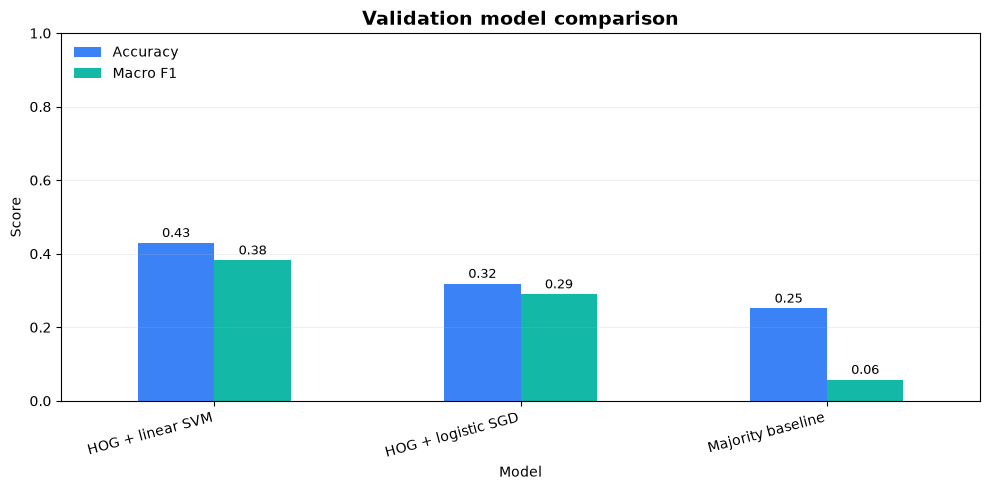

In [4]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)

candidate_factories = {
    "Majority baseline": lambda: DummyClassifier(strategy="most_frequent"),
    "HOG + logistic SGD": lambda: SGDClassifier(
        loss="log_loss", alpha=1e-4, max_iter=1000, tol=1e-3,
        class_weight="balanced", early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=5, random_state=RANDOM_STATE,
    ),
    "HOG + linear SVM": lambda: LinearSVC(
        C=1.0, class_weight="balanced", dual="auto", random_state=RANDOM_STATE, max_iter=3000,
    ),
}

validation_rows = []
candidate_models = {}
for name, factory in candidate_factories.items():
    model = factory()
    started = time.time()
    model.fit(X_fit, y_fit)
    predictions = model.predict(X_valid)
    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Macro F1": f1_score(y_valid, predictions, average="macro", zero_division=0),
        "Fit time (s)": time.time() - started,
    })
    candidate_models[name] = factory

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["Macro F1", "Accuracy"], ascending=False
).reset_index(drop=True)
display(validation_results.style.format({"Accuracy": "{:.3%}", "Macro F1": "{:.3%}", "Fit time (s)": "{:.1f}"}))
best_model_name = validation_results.loc[0, "Model"]
print(f"Selected on validation macro F1: {best_model_name}")

plot_data = validation_results.set_index("Model")[["Accuracy", "Macro F1"]]
ax = plot_data.plot(kind="bar", figsize=(10, 5), color=["#3B82F6", "#14B8A6"])
ax.set_title("Validation model comparison", weight="bold", fontsize=14)
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## Fit the selected model and evaluate once on the test set

The winning pipeline is refit on all training images. The separate test set is used only here for final reporting.

Selected model: HOG + linear SVM
Training accuracy: 55.470%
Held-out test accuracy: 43.912%
Held-out test macro F1: 39.302%
Held-out test weighted F1: 42.959%

Per-class test metrics:


,precision,recall,f1-score,support
angry,0.301552,0.283925,0.292473,958.00000
disgust,0.176471,0.513514,0.262673,111.00000
fear,0.307143,0.209961,0.249420,1024.00000
happy,0.598295,0.672492,0.633227,1774.00000
neutral,0.430567,0.424980,0.427755,1233.00000
sad,0.360489,0.283881,0.317631,1247.00000
surprise,0.506604,0.646209,0.567953,831.00000
accuracy,0.439120,0.439120,0.439120,0.43912
macro avg,0.383017,0.433566,0.393019,7178.00000
weighted avg,0.429893,0.439120,0.429587,7178.00000


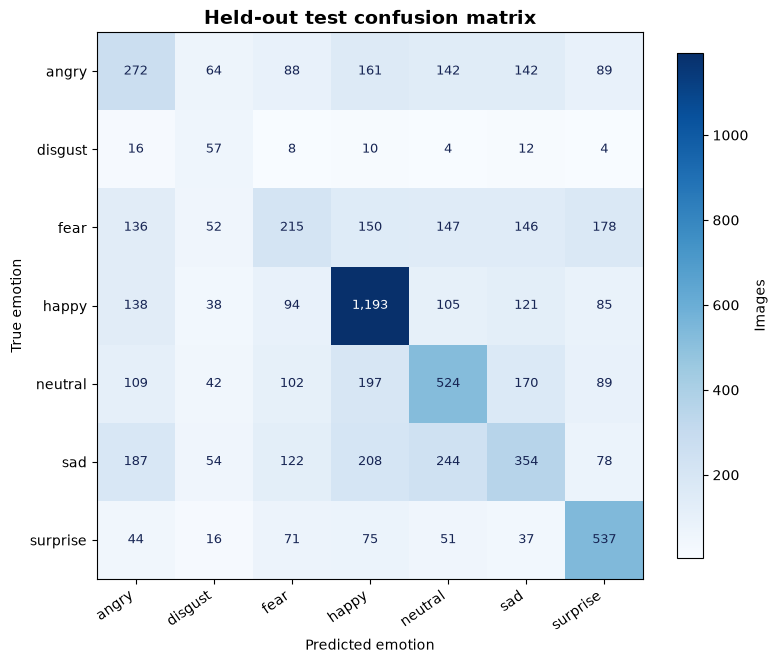

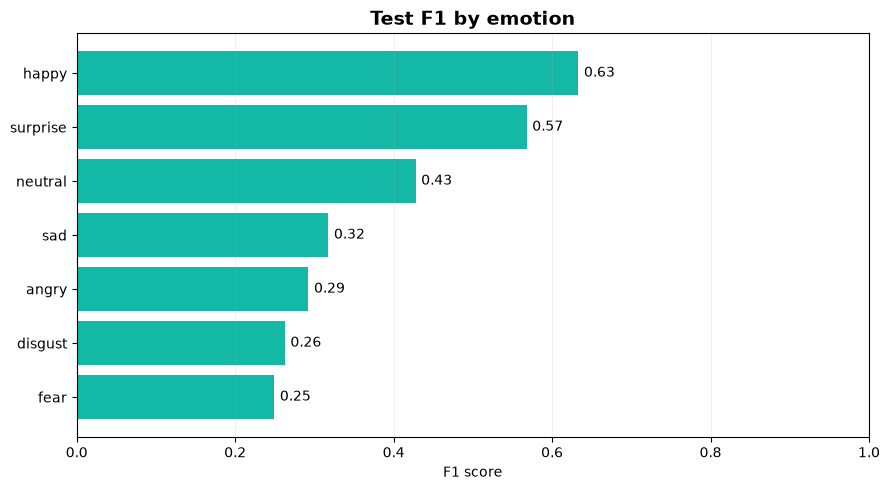

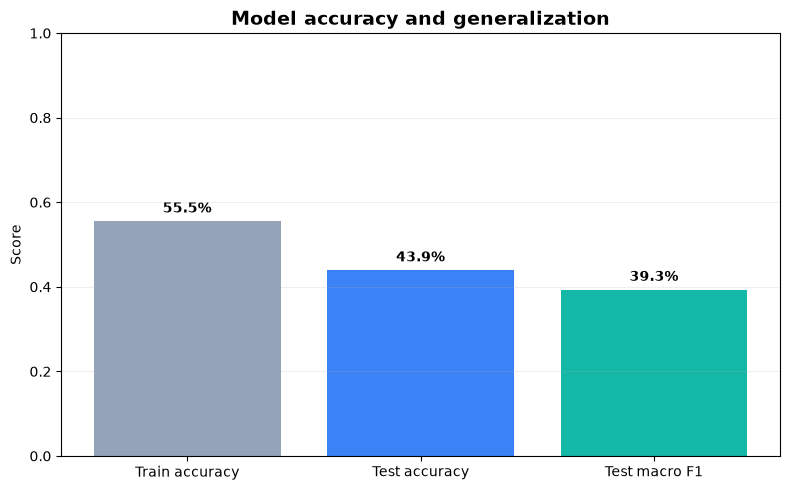

In [5]:
final_model = candidate_models[best_model_name]()
final_model.fit(X_train, y_train)
train_predictions = final_model.predict(X_train)
test_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test, test_predictions, average="weighted", zero_division=0)
train_accuracy = accuracy_score(y_train, train_predictions)
print(f"Selected model: {best_model_name}")
print(f"Training accuracy: {train_accuracy:.3%}")
print(f"Held-out test accuracy: {test_accuracy:.3%}")
print(f"Held-out test macro F1: {test_macro_f1:.3%}")
print(f"Held-out test weighted F1: {test_weighted_f1:.3%}")
print("\nPer-class test metrics:")
report = classification_report(y_test, test_predictions, labels=CLASS_NAMES, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T)

cm = confusion_matrix(y_test, test_predictions, labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(cm, cmap="Blues")
ax.set_title("Held-out test confusion matrix", weight="bold", fontsize=14)
ax.set_xlabel("Predicted emotion")
ax.set_ylabel("True emotion")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
threshold = cm.max() / 2
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(col, row, f"{cm[row, col]:,}", ha="center", va="center",
                color="white" if cm[row, col] > threshold else "#172554", fontsize=9)
fig.colorbar(image, ax=ax, shrink=0.82, label="Images")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

class_f1 = pd.Series({name: report[name]["f1-score"] for name in CLASS_NAMES}).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(class_f1.index, class_f1.values, color="#14B8A6")
ax.set_xlim(0, 1)
ax.set_xlabel("F1 score")
ax.set_title("Test F1 by emotion", weight="bold", fontsize=14)
ax.grid(axis="x", alpha=0.2)
ax.bar_label(bars, fmt="%.2f", padding=4)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_f1_by_emotion.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
metrics = pd.Series({"Train accuracy": train_accuracy, "Test accuracy": test_accuracy, "Test macro F1": test_macro_f1})
bars = ax.bar(metrics.index, metrics.values, color=["#94A3B8", "#3B82F6", "#14B8A6"])
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model accuracy and generalization", weight="bold", fontsize=14)
ax.grid(axis="y", alpha=0.2)
ax.bar_label(bars, labels=[f"{value:.1%}" for value in metrics.values], padding=4, weight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "accuracy_summary.png", dpi=180, bbox_inches="tight")
plt.show()

## Infographic and saved model

The final single-page infographic summarizes dataset size, selected approach, held-out accuracy, macro F1, and per-emotion test F1. The joblib artifact bundles the fitted pipeline and preprocessing/class metadata.

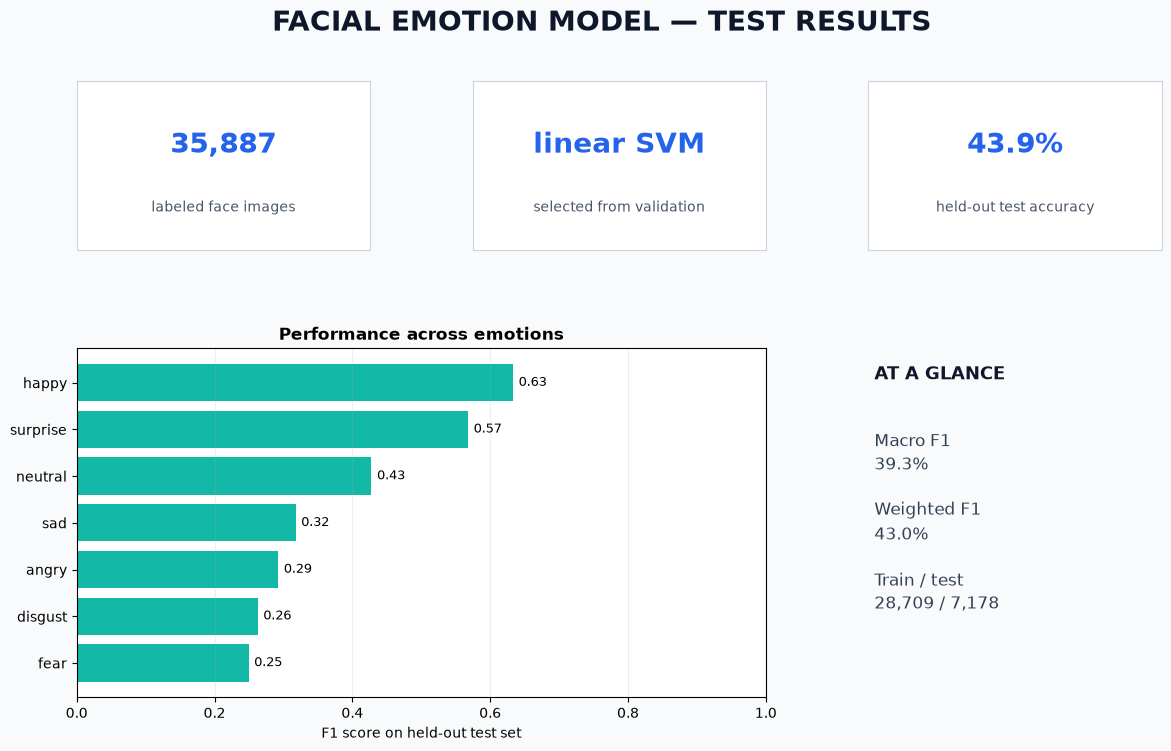

Saved model: C:\Users\POOJASRI M\Documents\suganth\cog-nito-care\ml\face_emotion\model\facial_emotion_hog_model.joblib
Saved charts: C:\Users\POOJASRI M\Documents\suganth\cog-nito-care\ml\face_emotion\outputs


In [6]:
fig = plt.figure(figsize=(14, 8), facecolor="#F8FAFC")
grid = fig.add_gridspec(2, 3, height_ratios=[0.65, 1.35], hspace=0.38, wspace=0.35)
fig.suptitle("FACIAL EMOTION MODEL — TEST RESULTS", fontsize=20, weight="bold", color="#0F172A", y=0.97)
cards = [
    (f"{train_counts.sum() + test_counts.sum():,}", "labeled face images"),
    (best_model_name.replace("HOG + ", ""), "selected from validation"),
    (f"{test_accuracy:.1%}", "held-out test accuracy"),
]
for col, (value, label) in enumerate(cards):
    ax = fig.add_subplot(grid[0, col])
    ax.set_facecolor("white")
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=20 if len(value) < 16 else 15,
            weight="bold", color="#2563EB", transform=ax.transAxes)
    ax.text(0.5, 0.25, label, ha="center", va="center", fontsize=10, color="#475569", transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_color("#CBD5E1")

ax = fig.add_subplot(grid[1, :2])
sorted_f1 = class_f1.sort_values()
bars = ax.barh(sorted_f1.index, sorted_f1.values, color="#14B8A6")
ax.set_xlim(0, 1)
ax.set_xlabel("F1 score on held-out test set")
ax.set_title("Performance across emotions", weight="bold")
ax.grid(axis="x", alpha=0.2)
ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)

ax = fig.add_subplot(grid[1, 2])
ax.axis("off")
ax.text(0.02, 0.95, "AT A GLANCE", fontsize=13, weight="bold", color="#0F172A", va="top")
ax.text(0.02, 0.77,
        f"Macro F1\n{test_macro_f1:.1%}\n\nWeighted F1\n{test_weighted_f1:.1%}\n\nTrain / test\n{train_counts.sum():,} / {test_counts.sum():,}",
        fontsize=12, color="#334155", va="top", linespacing=1.4)
fig.savefig(OUTPUT_DIR / "facial_emotion_infographic.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

artifact_path = MODEL_DIR / "facial_emotion_hog_model.joblib"
joblib.dump({
    "model": final_model,
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "feature_extractor": "skimage.feature.hog",
    "hog_config": HOG_CONFIG,
    "selected_model": best_model_name,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
}, artifact_path)

print(f"Saved model: {artifact_path}")
print(f"Saved charts: {OUTPUT_DIR}")